In [1]:
from pathlib import Path

DATASET_ROOT = Path(
    r"D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set"
)

print("Dataset path:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

Dataset path: D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set
Dataset exists: True


In [2]:
CLASS_FOLDERS = {
    "colon_aca": DATASET_ROOT / "colon_image_sets" / "colon_aca",
    "colon_n": DATASET_ROOT / "colon_image_sets" / "colon_n",
    "lung_aca": DATASET_ROOT / "lung_image_sets" / "lung_aca",
    "lung_n": DATASET_ROOT / "lung_image_sets" / "lung_n",
    "lung_scc": DATASET_ROOT / "lung_image_sets" / "lung_scc",
}

for class_name, folder in CLASS_FOLDERS.items():
    print(f"{class_name}: {folder.is_dir()}")

colon_aca: True
colon_n: True
lung_aca: True
lung_n: True
lung_scc: True


In [3]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

for class_name, folder in CLASS_FOLDERS.items():
    images = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    ]
    print(f"{class_name}: {len(images)} images")

colon_aca: 5000 images
colon_n: 5000 images
lung_aca: 5000 images
lung_n: 5000 images
lung_scc: 5000 images


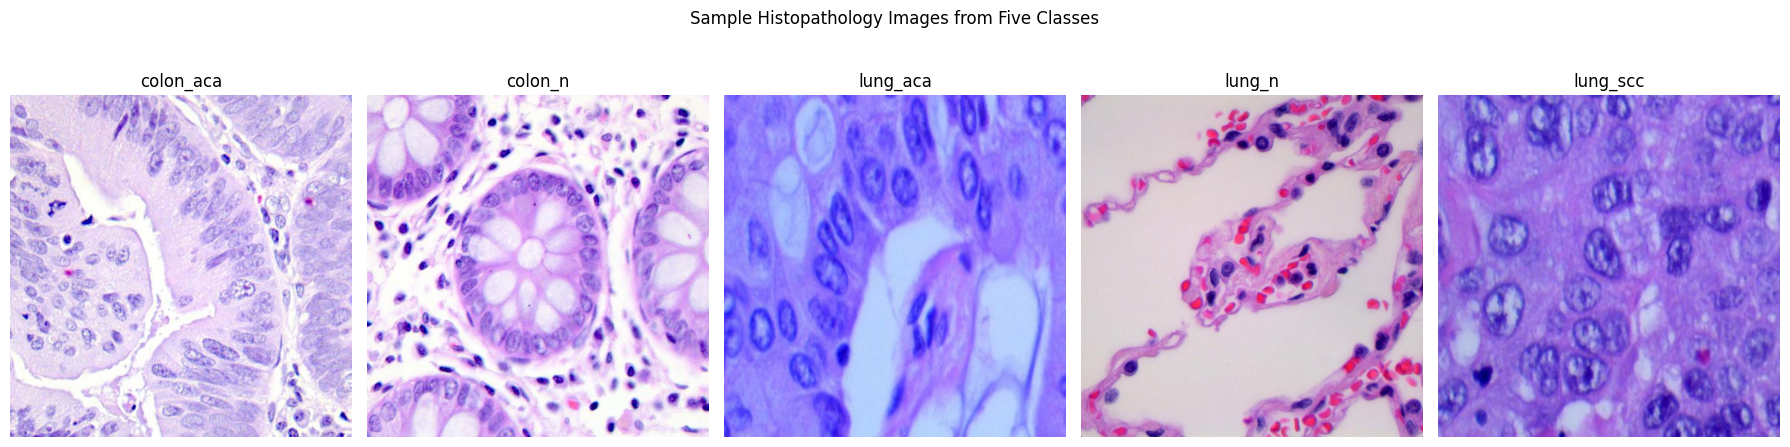

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (class_name, folder) in zip(axes, CLASS_FOLDERS.items()):
    image_files = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample Histopathology Images from Five Classes")
plt.tight_layout()
plt.show()

Number of images checked: 500

Image dimension counts:
(768, 768): 500 images


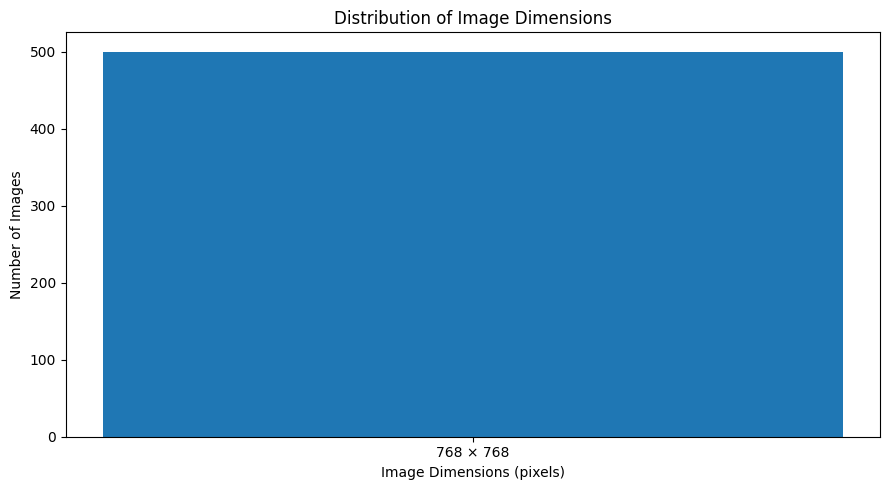

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter
import random

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

dimensions = []

for class_name, folder in CLASS_FOLDERS.items():
    image_files = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    # Check up to 100 randomly selected images per class
    sample_files = random.sample(
        image_files, min(100, len(image_files))
    )

    for image_path in sample_files:
        with Image.open(image_path) as img:
            dimensions.append(img.size)

dimension_counts = Counter(dimensions)

print("Number of images checked:", len(dimensions))
print("\nImage dimension counts:")

for size, count in dimension_counts.most_common():
    print(f"{size}: {count} images")

# Visualize the dimension distribution
plt.figure(figsize=(9, 5))

labels = [f"{w} × {h}" for w, h in dimension_counts.keys()]
counts = list(dimension_counts.values())

plt.bar(labels, counts)
plt.title("Distribution of Image Dimensions")
plt.xlabel("Image Dimensions (pixels)")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

In [6]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    roc_curve, auc, roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS_CNN = 3
EPOCHS_MOBILENET = 3

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU devices: []


In [7]:

from pathlib import Path

DATASET_ROOT = Path(
    r"D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set"
)
CLASS_FOLDERS = {
    "colon_aca": DATASET_ROOT / "colon_image_sets" / "colon_aca",
    "colon_n":   DATASET_ROOT / "colon_image_sets" / "colon_n",
    "lung_aca":  DATASET_ROOT / "lung_image_sets" / "lung_aca",
    "lung_n":    DATASET_ROOT / "lung_image_sets" / "lung_n",
    "lung_scc":  DATASET_ROOT / "lung_image_sets" / "lung_scc",
}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Dataset root:", DATASET_ROOT)
print("Root exists:", DATASET_ROOT.exists())

for class_name, folder in CLASS_FOLDERS.items():
    print(f"{class_name:12s} | exists={folder.is_dir()} | path={folder}")

Dataset root: D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set
Root exists: True
colon_aca    | exists=True | path=D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set\colon_image_sets\colon_aca
colon_n      | exists=True | path=D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set\colon_image_sets\colon_n
lung_aca     | exists=True | path=D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set\lung_image_sets\lung_aca
lung_n       | exists=True | path=D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set\lung_image_sets\lung_n
lung_scc     | exists=True | path=D:\ollamamodels\AI\Gen AI\project_final\data\lung_colon_image_set\lung_image_sets\lung_scc


In [8]:
records = []

for class_name, folder in CLASS_FOLDERS.items():
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Class folder not found: {folder}\n"
            "Update DATASET_ROOT so it points to the extracted lung_colon_image_set folder."
        )
    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({"image_path": str(path), "label": class_name})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("No images found. Check DATASET_ROOT and the folder structure.")

class_names = sorted(df["label"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}
df["label_id"] = df["label"].map(class_to_index).astype("int32")

print("Total images:", len(df))
display(df["label"].value_counts().reindex(class_names).rename("image_count").to_frame())
print("Class mapping:", class_to_index)

Total images: 25000


,image_count
label,
colon_aca,5000
colon_n,5000
lung_aca,5000
lung_n,5000
lung_scc,5000


Class mapping: {'colon_aca': 0, 'colon_n': 1, 'lung_aca': 2, 'lung_n': 3, 'lung_scc': 4}


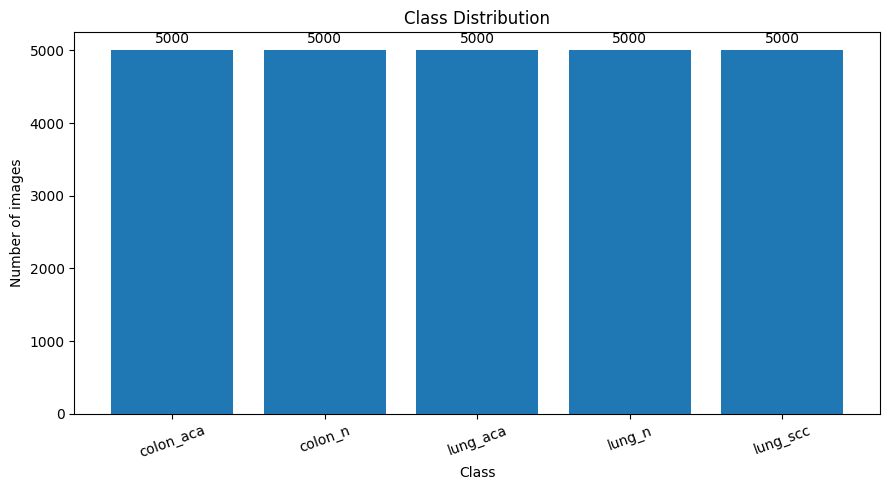

In [9]:
# Visualization 1: class distribution
counts = df["label"].value_counts().reindex(class_names)

plt.figure(figsize=(9, 5))
bars = plt.bar(counts.index, counts.values)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

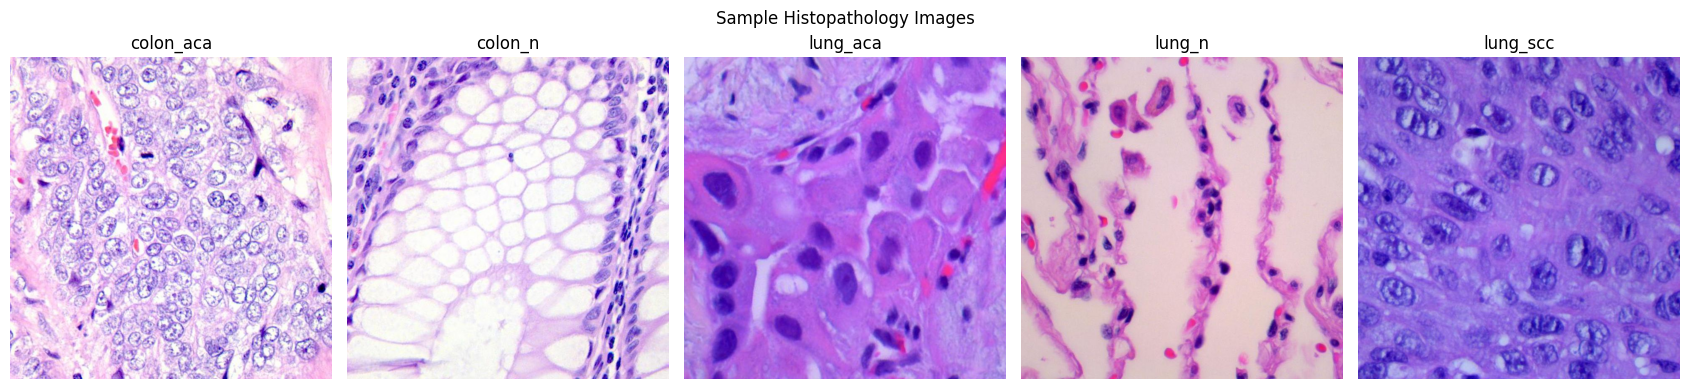

In [10]:
# Visualization 2: one sample image per class
fig, axes = plt.subplots(1, len(class_names), figsize=(17, 4))
for ax, class_name in zip(axes, class_names):
    sample_path = df.loc[df["label"] == class_name, "image_path"].iloc[0]
    with Image.open(sample_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(class_name)
    ax.axis("off")
plt.suptitle("Sample Histopathology Images")
plt.tight_layout()
plt.show()

In [11]:
# Visualization 3: dimensions of up to 20 images per class
from collections import Counter

dimension_counts = Counter()
for class_name, folder in CLASS_FOLDERS.items():
    paths = [p for p in folder.iterdir()
             if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    for path in paths[:20]:
        try:
            with Image.open(path) as image:
                dimension_counts[image.size] += 1
        except Exception as exc:
            print("Could not read:", path, exc)

print("Sampled image dimensions:")
for size, count in dimension_counts.most_common():
    print(f"{size}: {count} images")

Sampled image dimensions:
(768, 768): 100 images


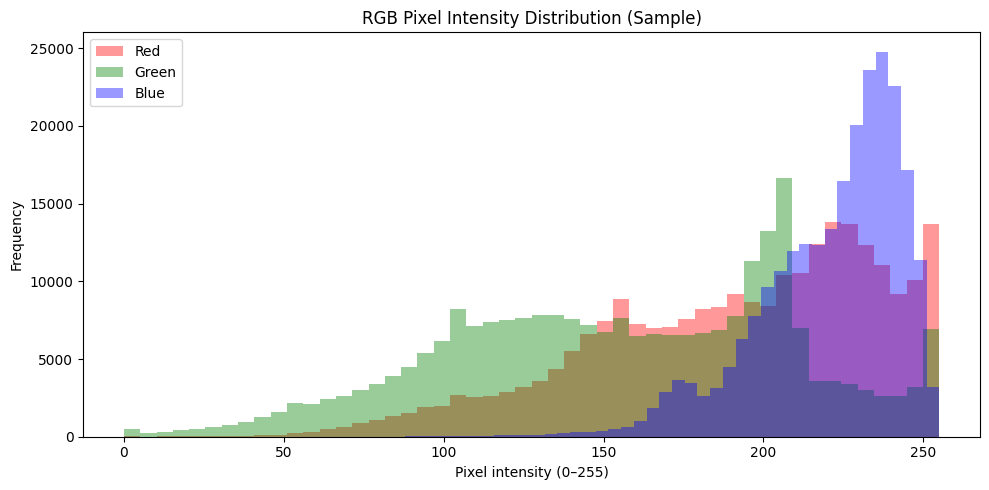

In [12]:
# Visualization 4: RGB intensity distribution from 5 images per class
rgb_samples = []
for class_name in class_names:
    paths = df.loc[df["label"] == class_name, "image_path"].head(5)
    for path in paths:
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("RGB").resize((100, 100)))
            rgb_samples.append(pixels.reshape(-1, 3))

rgb_values = np.concatenate(rgb_samples, axis=0)
plt.figure(figsize=(10, 5))
for channel, color, name in [(0, "red", "Red"), (1, "green", "Green"), (2, "blue", "Blue")]:
    plt.hist(rgb_values[:, channel], bins=50, alpha=0.4, color=color, label=name)
plt.title("RGB Pixel Intensity Distribution (Sample)")
plt.xlabel("Pixel intensity (0–255)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["label_id"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label_id"]
)

print(f"Train: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test: {len(test_df):,}")
print("\nTraining class counts:")
print(train_df["label"].value_counts().reindex(class_names))

Train: 17,500
Validation: 3,750
Test: 3,750

Training class counts:
label
colon_aca    3500
colon_n      3500
lung_aca     3500
lung_n       3500
lung_scc     3500
Name: count, dtype: int64


Image batch: (16, 224, 224, 3)
Label batch: (16,)
Pixel range: 0.0 to 1.0


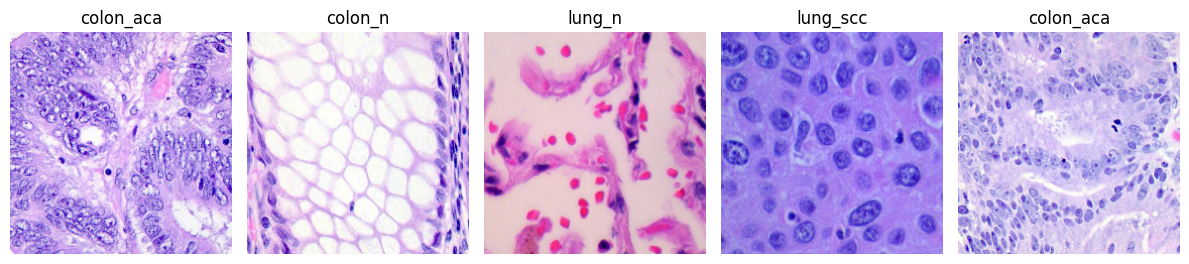

In [14]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.05),
], name="data_augmentation")

def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(frame, training=False):
    paths = frame["image_path"].values
    labels = frame["label_id"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(frame), 2000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

images, labels_batch = next(iter(train_ds))
print("Image batch:", images.shape)
print("Label batch:", labels_batch.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].numpy())
    ax.set_title(class_names[int(labels_batch[i].numpy())])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
num_classes = len(class_names)

cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
], name="custom_cnn")

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [16]:
callbacks_cnn = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "custom_cnn_best.keras", monitor="val_loss", save_best_only=True
    )
]

history_cnn = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    callbacks=callbacks_cnn
)

Epoch 1/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 2046s 2s/step - accuracy: 0.8581 - loss: 0.3693 - val_accuracy: 0.8189 - val_loss: 0.6653 - learning_rate: 0.0010
Epoch 2/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 1079s 986ms/step - accuracy: 0.9090 - loss: 0.2387 - val_accuracy: 0.7832 - val_loss: 0.6803 - learning_rate: 0.0010
Epoch 3/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 1598s 1s/step - accuracy: 0.9325 - loss: 0.1695 - val_accuracy: 0.8720 - val_loss: 0.3014 - learning_rate: 0.0010


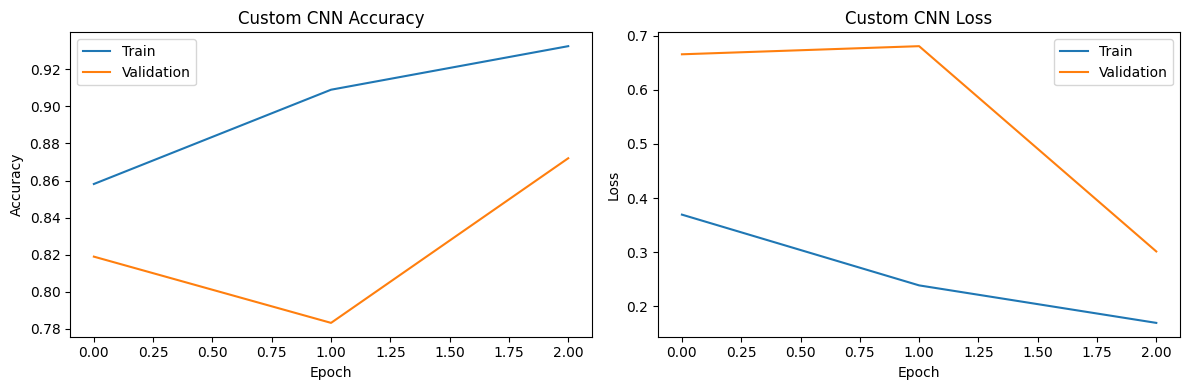

In [17]:
def plot_learning_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title} Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(f"{title} Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_learning_curves(history_cnn, "Custom CNN")

In [18]:
# MobileNetV2 preprocessing expects pixel values in [0, 255] before preprocess_input.
# Input pipeline currently returns [0, 1], so this mapping prepares a separate dataset.
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def prepare_mobilenet(images, labels):
    images = preprocess_input(images * 255.0)
    return images, labels

mobilenet_train_ds = train_ds.map(prepare_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
mobilenet_val_ds = val_ds.map(prepare_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
mobilenet_test_ds = test_ds.map(prepare_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)

base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet", include_top=False, input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
mobilenet = tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer")

mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 124s 13us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │           6,405 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
callbacks_mobilenet = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "mobilenetv2_best.keras", monitor="val_loss", save_best_only=True
    )
]

history_mobilenet = mobilenet.fit(
    mobilenet_train_ds,
    validation_data=mobilenet_val_ds,
    epochs=EPOCHS_MOBILENET,
    callbacks=callbacks_mobilenet
)

Epoch 1/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 1213s 1s/step - accuracy: 0.9281 - loss: 0.2034 - val_accuracy: 0.9637 - val_loss: 0.1065 - learning_rate: 0.0010
Epoch 2/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 787s 693ms/step - accuracy: 0.9615 - loss: 0.1054 - val_accuracy: 0.9728 - val_loss: 0.0834 - learning_rate: 0.0010
Epoch 3/3
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 461s 382ms/step - accuracy: 0.9663 - loss: 0.0908 - val_accuracy: 0.9757 - val_loss: 0.0759 - learning_rate: 0.0010


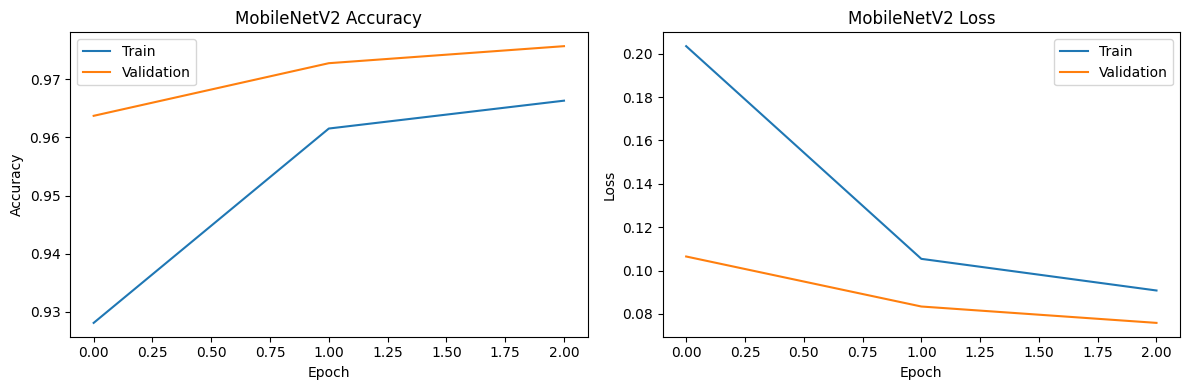

In [20]:
plot_learning_curves(history_mobilenet, "MobileNetV2")

235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 210ms/step

Custom CNN classification report:
              precision    recall  f1-score   support

   colon_aca       0.97      0.96      0.97       750
     colon_n       0.97      0.97      0.97       750
    lung_aca       0.66      0.98      0.79       750
      lung_n       0.98      1.00      0.99       750
    lung_scc       1.00      0.50      0.66       750

    accuracy                           0.88      3750
   macro avg       0.92      0.88      0.87      3750
weighted avg       0.92      0.88      0.87      3750



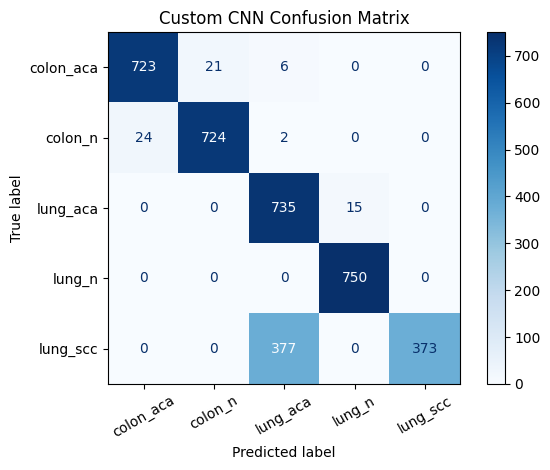

235/235 ━━━━━━━━━━━━━━━━━━━━ 72s 302ms/step

MobileNetV2 classification report:
              precision    recall  f1-score   support

   colon_aca       0.99      0.99      0.99       750
     colon_n       1.00      0.99      1.00       750
    lung_aca       0.98      0.92      0.95       750
      lung_n       1.00      1.00      1.00       750
    lung_scc       0.92      0.98      0.95       750

    accuracy                           0.98      3750
   macro avg       0.98      0.98      0.98      3750
weighted avg       0.98      0.98      0.98      3750



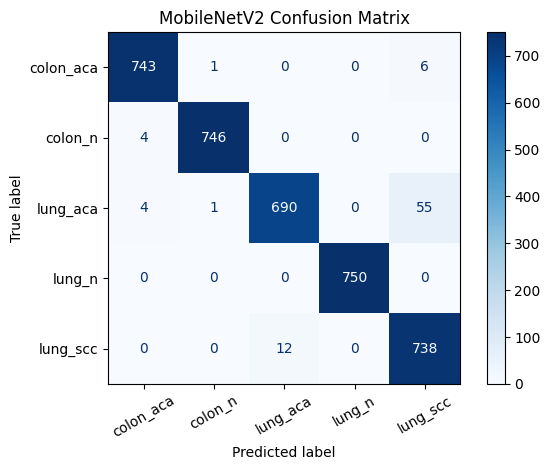

In [21]:
def evaluate_model(model, dataset, model_name):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    y_prob = model.predict(dataset, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

    print(f"\n{model_name} classification report:")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=class_names, xticks_rotation=30, cmap="Blues"
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return metrics, y_true, y_prob, y_pred

from sklearn.metrics import ConfusionMatrixDisplay

cnn_metrics, y_true_cnn, y_prob_cnn, y_pred_cnn = evaluate_model(cnn, test_ds, "Custom CNN")
mobilenet_metrics, y_true_mob, y_prob_mob, y_pred_mob = evaluate_model(
    mobilenet, mobilenet_test_ds, "MobileNetV2"
)

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Balanced accuracy,MCC
0,Custom CNN,0.8813,0.9153,0.8813,0.8750,0.8813,0.8624
1,MobileNetV2,0.9779,0.9786,0.9779,0.9779,0.9779,0.9725


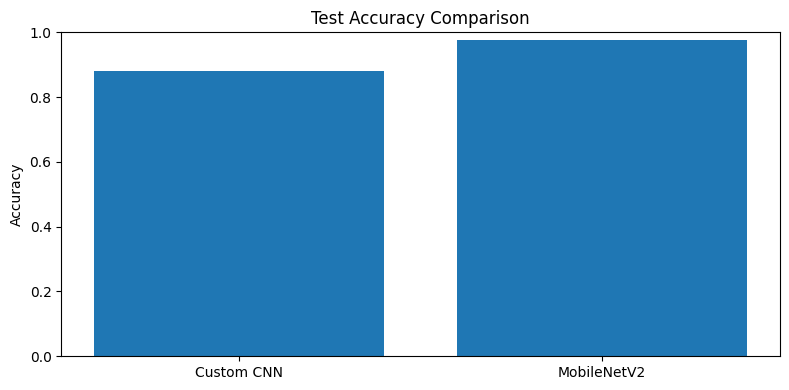

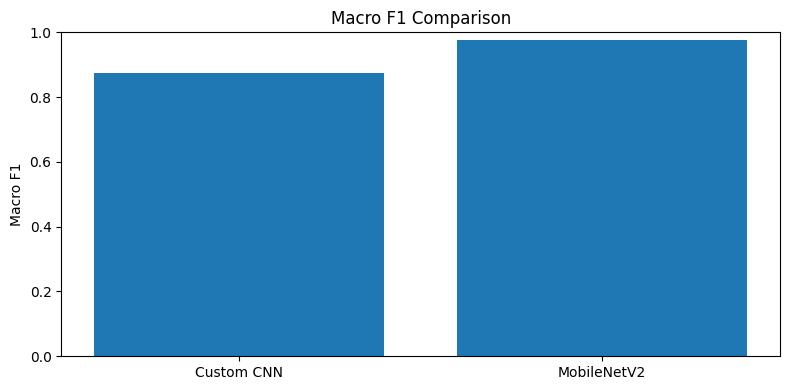

In [22]:
comparison = pd.DataFrame([cnn_metrics, mobilenet_metrics])
display(comparison.round(4))

plt.figure(figsize=(8, 4))
plt.bar(comparison["Model"], comparison["Accuracy"])
plt.title("Test Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(comparison["Model"], comparison["Macro F1"])
plt.title("Macro F1 Comparison")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

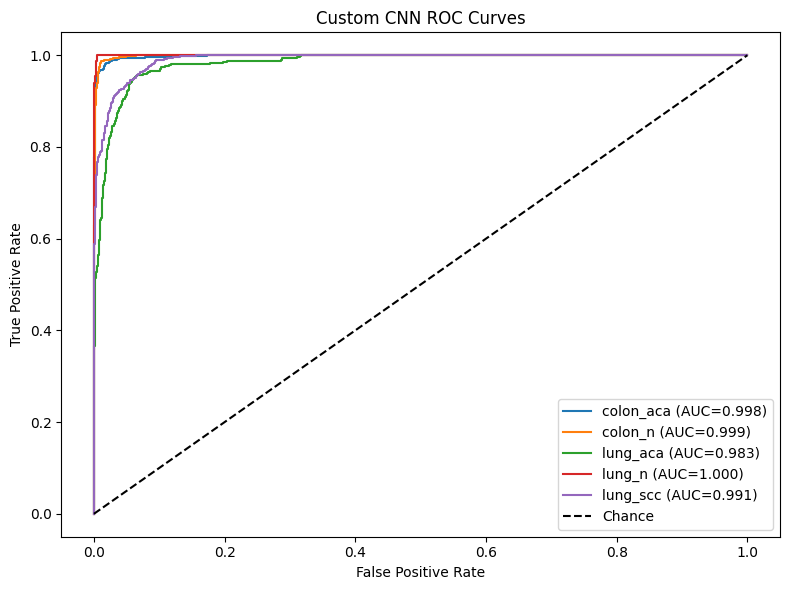

Macro ROC-AUC: 0.994


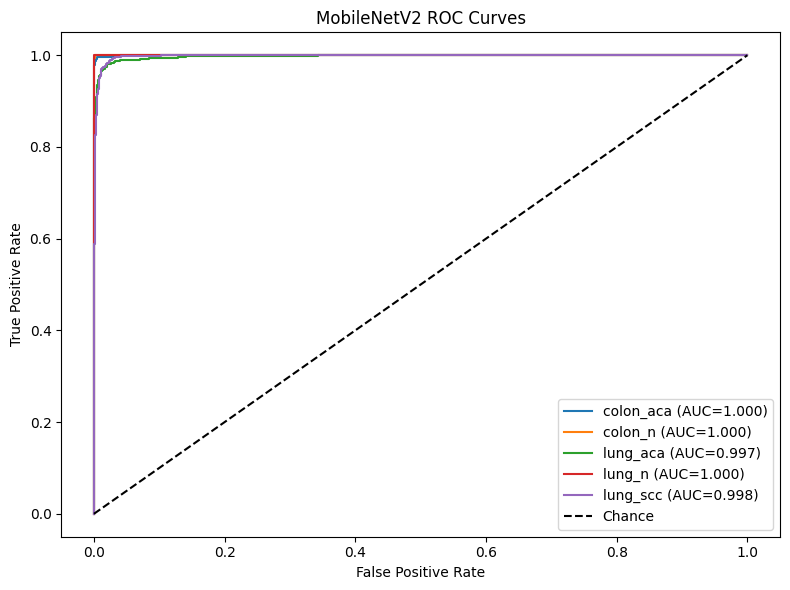

Macro ROC-AUC: 0.999


In [23]:
def plot_multiclass_roc(y_true, y_prob, title):
    y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))
    plt.figure(figsize=(8, 6))
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        class_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Chance")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    print("Macro ROC-AUC:", round(roc_auc_score(y_true_bin, y_prob, average="macro", multi_class="ovr"), 4))

plot_multiclass_roc(y_true_cnn, y_prob_cnn, "Custom CNN ROC Curves")
plot_multiclass_roc(y_true_mob, y_prob_mob, "MobileNetV2 ROC Curves")

In [24]:
cnn.save("custom_cnn_final.keras")
mobilenet.save("mobilenetv2_final.keras")

pd.DataFrame({
    "class_name": class_names,
    "class_index": list(range(len(class_names)))
}).to_csv("class_mapping.csv", index=False)

comparison.to_csv("model_comparison.csv", index=False)

print("Saved:")
print("- custom_cnn_final.keras")
print("- mobilenetv2_final.keras")
print("- class_mapping.csv")
print("- model_comparison.csv")

Saved:
- custom_cnn_final.keras
- mobilenetv2_final.keras
- class_mapping.csv
- model_comparison.csv
